In [13]:
!pip install pennylane torch torchvision kagglehub scikit-learn seaborn grad-cam pydicom --quiet

print("✅ All packages installed successfully")
print("Note: Using lightning.qubit (CPU) - lightning.gpu is Linux only")

✅ All packages installed successfully
Note: Using lightning.qubit (CPU) - lightning.gpu is Linux only


In [14]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler, ConcatDataset, Dataset
from torchvision import datasets, models, transforms
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import warnings
warnings.filterwarnings("ignore")

# Grad-CAM imports
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# Medical imaging
import pydicom
from PIL import Image
from collections import Counter
from torch.optim.lr_scheduler import OneCycleLR

# Quantum machine learning
import pennylane as qml

# ── Device Configuration ─────────────────────────────────────────────
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    print(f"✅ GPU detected: {torch.cuda.get_device_name(0)}")
    # Enable TF32 for Ampere GPUs (RTX 3060/4060) - massive speedup
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    torch.backends.cudnn.benchmark = True
else:
    DEVICE = torch.device("cpu")
    print("⚠️  No CUDA GPU found — running on CPU")

# Hyperparameters
N_QUBITS = 4
BATCH = 32 if torch.cuda.is_available() else 16
SEED = 42

# ── Save Directory Setup ─────────────────────────────────────────────
if os.path.exists("/kaggle/working"):
    SAVE_DIR = "/kaggle/working"
elif os.path.exists("/content"):
    SAVE_DIR = "/content/qcnn_checkpoints"
else:
    SAVE_DIR = os.path.join(os.path.expanduser("~"), "qcnn_checkpoints")

os.makedirs(SAVE_DIR, exist_ok=True)

# Set seeds
torch.manual_seed(SEED)
np.random.seed(SEED)

print(f"\n{'═'*60}")
print(f"Configuration Summary:")
print(f"  Device: {DEVICE}")
print(f"  Qubits: {N_QUBITS}")
print(f"  Batch size: {BATCH}")
print(f"  Save directory: {SAVE_DIR}")
print(f"{'═'*60}")

⚠️  No CUDA GPU found — running on CPU

════════════════════════════════════════════════════════════
Configuration Summary:
  Device: cpu
  Qubits: 4
  Batch size: 16
  Save directory: C:\Users\rames\qcnn_checkpoints
════════════════════════════════════════════════════════════


In [15]:
import os

# ── ICMR Dataset Path (your local path + fallbacks) ──────────────────
if os.path.exists("/kaggle/input/datasets/sowmyaabirami/icmr-tuberclosis-dataset/intbtr254"):
    ICMR_ROOT = "/kaggle/input/datasets/sowmyaabirami/icmr-tuberclosis-dataset/intbtr254"
elif os.path.exists("/content/intbtr254"):
    ICMR_ROOT = "/content/intbtr254"
elif os.path.exists(r"C:\Users\rames\OneDrive\Documents\All coding projects\QML Tuberclosis project\intbtr254"):
    ICMR_ROOT = r"C:\Users\rames\OneDrive\Documents\All coding projects\QML Tuberclosis project\intbtr254"
else:
    ICMR_ROOT = os.path.join(os.path.expanduser("~"), "datasets", "intbtr254")

print(f"ICMR path: {ICMR_ROOT}")
print(f"ICMR exists: {os.path.exists(ICMR_ROOT)}")

# ── Download Kaggle datasets ────────────────────────────────────────
print("\n⬇️  Downloading Kaggle datasets...")
path1 = kagglehub.dataset_download("tawsifurrahman/tuberculosis-tb-chest-xray-dataset")
path2 = kagglehub.dataset_download("tirthachhetri/tuberclosis-dataset")
print(f"DB1 (tawsifurrahman): {path1}")
print(f"DB2 (tirthachhetri): {path2}")

# ── Path Discovery Helper ──────────────────────────────────────────
def find_dir(root, target):
    """Walk directory tree to find folder matching target name"""
    for dirpath, dirnames, _ in os.walk(root):
        if os.path.basename(dirpath) == target:
            return dirpath
    return root

# Discover dataset structures
db1_root = find_dir(path1, "TB_Chest_Radiography_Database")
tb_train = find_dir(path2, "train")
tb_val = find_dir(path2, "valid")
tb_test = find_dir(path2, "test")

print(f"\n{'─'*60}")
print("Discovered paths:")
print(f"  DB1 root: {db1_root}")
print(f"  Train: {tb_train}")
print(f"  Val: {tb_val}")
print(f"  Test: {tb_test}")
print(f"{'─'*60}")

ICMR path: C:\Users\rames\OneDrive\Documents\All coding projects\QML Tuberclosis project\intbtr254
ICMR exists: True

⬇️  Downloading Kaggle datasets...
DB1 (tawsifurrahman): C:\Users\rames\.cache\kagglehub\datasets\tawsifurrahman\tuberculosis-tb-chest-xray-dataset\versions\3
DB2 (tirthachhetri): C:\Users\rames\.cache\kagglehub\datasets\tirthachhetri\tuberclosis-dataset\versions\1

────────────────────────────────────────────────────────────
Discovered paths:
  DB1 root: C:\Users\rames\.cache\kagglehub\datasets\tawsifurrahman\tuberculosis-tb-chest-xray-dataset\versions\3\TB_Chest_Radiography_Database
  Train: C:\Users\rames\.cache\kagglehub\datasets\tirthachhetri\tuberclosis-dataset\versions\1\TB_split\train
  Val: C:\Users\rames\.cache\kagglehub\datasets\tirthachhetri\tuberclosis-dataset\versions\1\TB_split\valid
  Test: C:\Users\rames\.cache\kagglehub\datasets\tirthachhetri\tuberclosis-dataset\versions\1\TB_split\test
────────────────────────────────────────────────────────────


In [16]:
# Training: Heavy augmentation to prevent overfitting
train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ColorJitter(brightness=0.3, contrast=0.3),
    transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.0)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    transforms.RandomErasing(p=0.2)  # Cutout regularization
])

# Validation/Test: Only normalization
val_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

print("✅ Transforms defined")
print(f"  Training augmentations: 9 transforms including RandomErasing")
print(f"  Validation: Resize + Normalize only")

✅ Transforms defined
  Training augmentations: 9 transforms including RandomErasing
  Validation: Resize + Normalize only


In [17]:
class DICOMDataset(Dataset):
    """
    All 162 ICMR files are Abnormal (class index 1).
    Converts DICOM pixel arrays to normalized RGB PIL Images.
    """
    def __init__(self, folder, transform=None):
        self.files = sorted([
            os.path.join(folder, f) for f in os.listdir(folder)
            if f.lower().endswith(".dicom")
        ])
        self.transform = transform
        print(f"DICOMDataset: Found {len(self.files)} files in {folder}")

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        # Read DICOM
        dcm = pydicom.dcmread(self.files[idx])
        arr = dcm.pixel_array.astype(np.float32)
        
        # Normalize to 0-255
        arr = (arr - arr.min()) / (arr.max() - arr.min() + 1e-8) * 255
        
        # Convert to PIL RGB
        img = Image.fromarray(arr.astype(np.uint8)).convert("RGB")
        
        if self.transform:
            img = self.transform(img)
            
        return img, 1  # All ICMR are TB-positive (class 1)

# Test the DICOM loader
if os.path.exists(ICMR_ROOT):
    icmr_test = DICOMDataset(ICMR_ROOT, transform=None)
    print(f"\n✅ DICOM dataset working: {len(icmr_test)} samples")
else:
    print(f"\n⚠️  ICMR path not found: {ICMR_ROOT}")

DICOMDataset: Found 162 files in C:\Users\rames\OneDrive\Documents\All coding projects\QML Tuberclosis project\intbtr254

✅ DICOM dataset working: 162 samples


In [18]:
# ═══════════════════════════════════════════════════════════════════
# FAST Dataset Loading - No iteration for counting
# ═══════════════════════════════════════════════════════════════════

# Create datasets
icmr_ds = DICOMDataset(ICMR_ROOT, transform=train_tf) if os.path.exists(ICMR_ROOT) else None
extra_ds = datasets.ImageFolder(db1_root, transform=train_tf)
split_train = datasets.ImageFolder(tb_train, transform=train_tf)
val_ds = datasets.ImageFolder(tb_val, transform=val_tf)
test_ds = datasets.ImageFolder(tb_test, transform=val_tf)

# Merge training datasets
datasets_to_merge = [split_train, extra_ds]
if icmr_ds:
    datasets_to_merge.append(icmr_ds)
    
train_ds = ConcatDataset(datasets_to_merge)
classes = split_train.classes

print(f"\n{'═'*60}")
print("Dataset Summary:")
print(f"{'─'*60}")

# FAST counting - use internal attributes, no iteration
def fast_count(dataset):
    """Extract labels without loading images"""
    if hasattr(dataset, 'samples'):
        # ImageFolder style - just count the list
        return Counter([s[1] for s in dataset.samples])
    elif hasattr(dataset, 'targets'):
        # TensorDataset style
        return Counter(dataset.targets)
    elif hasattr(dataset, 'datasets'):
        # ConcatDataset - sum counts of components
        total = Counter()
        for ds in dataset.datasets:
            total.update(fast_count(ds))
        return total
    else:
        # Fallback - only if necessary
        return Counter([dataset[i][1] for i in range(len(dataset))])

# Get counts instantly
split_counts = fast_count(split_train)
extra_counts = fast_count(extra_ds)
icmr_counts = Counter({1: len(icmr_ds)}) if icmr_ds else Counter()
total_counts = fast_count(train_ds)  # Uses ConcatDataset fast path

print(f"{'Source':<25} {'Normal':>10} {'TB/Abnormal':>12} {'Total':>8}")
print(f"{'─'*60}")
print(f"{'tirthachhetri train':<25} {split_counts.get(0, 0):>10} {split_counts.get(1, 0):>12} {len(split_train):>8}")
print(f"{'tawsifurrahman DB1':<25} {extra_counts.get(0, 0):>10} {extra_counts.get(1, 0):>12} {len(extra_ds):>8}")
if icmr_ds:
    print(f"{'ICMR DICOM':<25} {icmr_counts.get(0, 0):>10} {icmr_counts.get(1, 0):>12} {len(icmr_ds):>8}")
print(f"{'─'*60}")
print(f"{'TOTAL TRAIN':<25} {total_counts.get(0, 0):>10} {total_counts.get(1, 0):>12} {len(train_ds):>8}")
print(f"{'─'*60}")
print(f"\nValidation: {len(val_ds):,} images")
print(f"Test: {len(test_ds):,} images")
print(f"\nClasses: {classes}")
print(f"{'═'*60}")
print("\n✅ Dataset ready (fast count - no image loading)")

DICOMDataset: Found 162 files in C:\Users\rames\OneDrive\Documents\All coding projects\QML Tuberclosis project\intbtr254

════════════════════════════════════════════════════════════
Dataset Summary:
────────────────────────────────────────────────────────────
Source                        Normal  TB/Abnormal    Total
────────────────────────────────────────────────────────────
tirthachhetri train             6228         3309     9537
tawsifurrahman DB1              3500          700     4200
ICMR DICOM                         0          162      162
────────────────────────────────────────────────────────────
TOTAL TRAIN                     9728         4171    13899
────────────────────────────────────────────────────────────

Validation: 1,288 images
Test: 1,936 images

Classes: ['healthy', 'tb']
════════════════════════════════════════════════════════════

✅ Dataset ready (fast count - no image loading)


In [19]:
# ═══════════════════════════════════════════════════════════════════
# CELL 7: Create DataLoaders with weighted sampling
# ═══════════════════════════════════════════════════════════════════

# Get all training labels for weight calculation
train_labels = []
for i in range(len(train_ds)):
    _, label = train_ds[i]
    train_labels.append(label)

# Calculate class weights (inverse frequency)
counts_arr = np.bincount(train_labels)
print(f"Class distribution: {counts_arr}")
print(f"Class weights: {1.0/counts_arr}")

# Create sample weights
weights = (1.0 / counts_arr[train_labels]).tolist()
sampler = WeightedRandomSampler(weights, len(weights), replacement=True)

# Num workers: 0 for Windows (avoids multiprocessing issues), 2 for Linux
num_workers = 0 if os.name == 'nt' else 2

# Create loaders
train_loader = DataLoader(
    train_ds, 
    batch_size=BATCH, 
    sampler=sampler, 
    num_workers=num_workers,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_ds, 
    batch_size=BATCH, 
    shuffle=False, 
    num_workers=num_workers,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_ds, 
    batch_size=BATCH, 
    shuffle=False, 
    num_workers=num_workers,
    pin_memory=torch.cuda.is_available()
)

print(f"\n{'═'*60}")
print("DataLoader Summary:")
print(f"{'─'*60}")
print(f"{'Loader':<15} {'Images':>10} {'Batches':>12} {'Batch Size':>12}")
print(f"{'─'*60}")
print(f"{'train_loader':<15} {len(train_ds):>10,} {len(train_loader):>12} {BATCH:>12}")
print(f"{'val_loader':<15} {len(val_ds):>10,} {len(val_loader):>12} {BATCH:>12}")
print(f"{'test_loader':<15} {len(test_ds):>10,} {len(test_loader):>12} {BATCH:>12}")
print(f"{'═'*60}")
print(f"\n✅ DataLoaders ready with weighted sampling for class balance")

Class distribution: [9728 4171]
Class weights: [0.0001028  0.00023975]

════════════════════════════════════════════════════════════
DataLoader Summary:
────────────────────────────────────────────────────────────
Loader              Images      Batches   Batch Size
────────────────────────────────────────────────────────────
train_loader        13,899          869           16
val_loader           1,288           81           16
test_loader          1,936          121           16
════════════════════════════════════════════════════════════

✅ DataLoaders ready with weighted sampling for class balance


In [21]:
dev = qml.device("lightning.qubit", wires=N_QUBITS, shots=None)

print(f"✅ PennyLane device initialized")
print(f"  Device: lightning.qubit")
print(f"  Wires: {N_QUBITS}")
print(f"  Shots: {dev.shots} (None = exact expectation values)")
print(f"  Platform: Windows compatible (lightning.qubit)")
print(f"  Note: lightning.gpu requires Linux + cuQuantum SDK")

✅ PennyLane device initialized
  Device: lightning.qubit
  Wires: 4
  Shots: Shots(total=None) (None = exact expectation values)
  Platform: Windows compatible (lightning.qubit)
  Note: lightning.gpu requires Linux + cuQuantum SDK


✅ Quantum circuit test passed
  Input shape: torch.Size([4])
  Output: -0.1460
  Output type: <class 'torch.Tensor'>

════════════════════════════════════════════════════════════
Circuit diagram (test with dummy values):
════════════════════════════════════════════════════════════


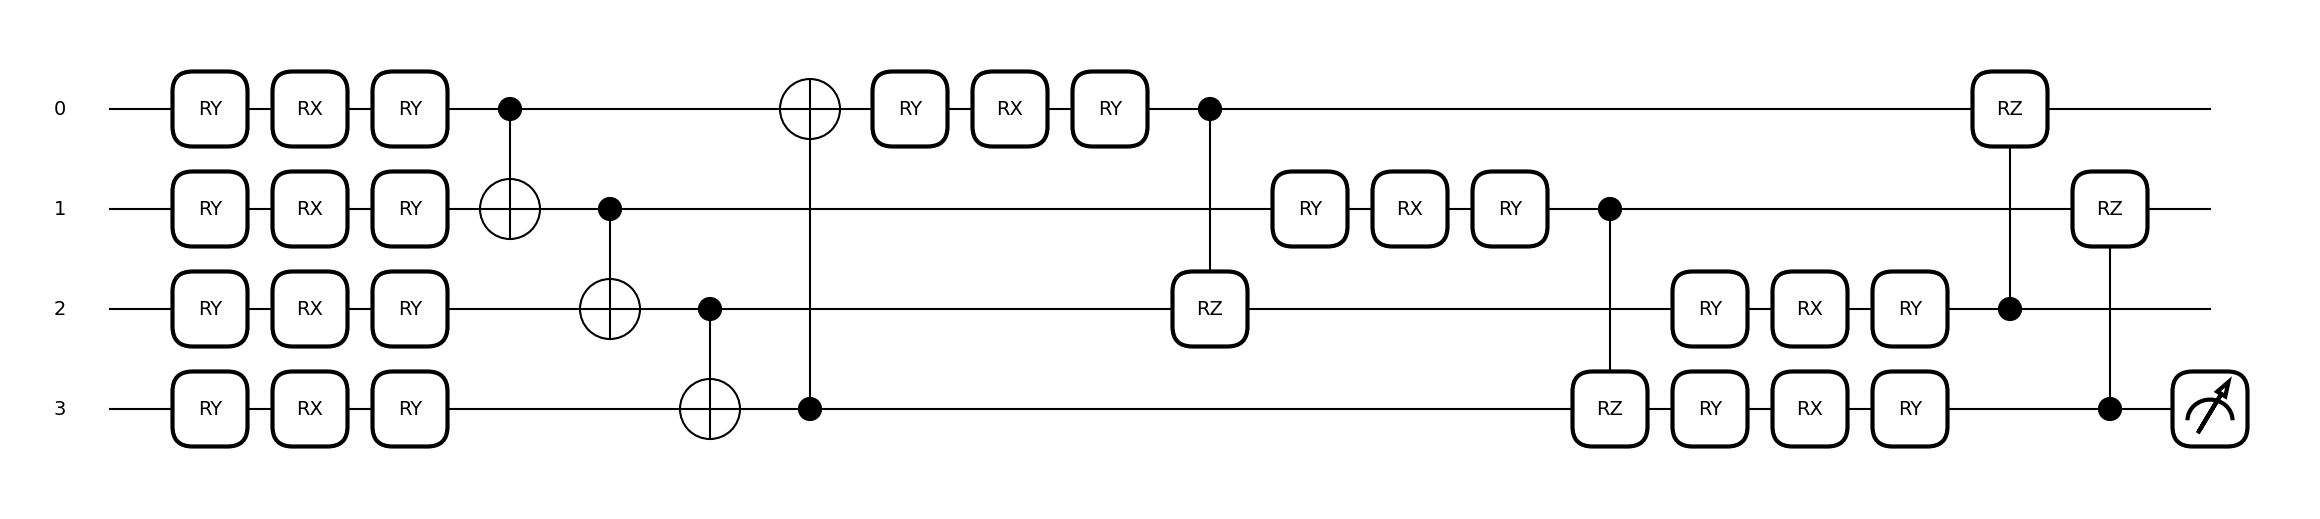

In [22]:
@qml.qnode(dev, interface="torch", diff_method="adjoint")
def quantum_circuit(inputs, weights_layer1, weights_layer2, weights_entangle):
    """
    Optimized 2-layer circuit with data re-uploading.
    Depth: ~12 gates (vs ~25 in original Qiskit circuit)
    
    Args:
        inputs: [n_qubits] tensor from classical network
        weights_layer1: [n_qubits, 2] rotation params
        weights_layer2: [n_qubits, 2] rotation params  
        weights_entangle: [n_qubits] entanglement params
    """
    
    # ═══ LAYER 1: Initial encoding + local rotations ═══
    for i in range(N_QUBITS):
        # Encode classical data as rotation angle
        qml.RY(inputs[i] * np.pi, wires=i)
        # Learnable rotations
        qml.RX(weights_layer1[i, 0], wires=i)
        qml.RY(weights_layer1[i, 1], wires=i)
    
    # Ring entanglement (efficient topology)
    for i in range(N_QUBITS):
        qml.CNOT(wires=[i, (i+1) % N_QUBITS])
    
    # ═══ LAYER 2: Data re-uploading + entanglement ═══
    for i in range(N_QUBITS):
        # Re-upload scaled data (expressivity without depth)
        qml.RY(inputs[i] * np.pi * 0.5, wires=i)
        # Second set of learnable rotations
        qml.RX(weights_layer2[i, 0], wires=i)
        qml.RY(weights_layer2[i, 1], wires=i)
        # Long-range entanglement
        qml.CRZ(weights_entangle[i], wires=[i, (i+2) % N_QUBITS])
    
    # Measurement: Pauli-Z on last qubit
    return qml.expval(qml.PauliZ(N_QUBITS-1))

# Test the circuit
test_input = torch.randn(N_QUBITS)
test_w1 = torch.randn(N_QUBITS, 2) * 0.1
test_w2 = torch.randn(N_QUBITS, 2) * 0.1
test_we = torch.randn(N_QUBITS) * 0.1

result = quantum_circuit(test_input, test_w1, test_w2, test_we)
print(f"✅ Quantum circuit test passed")
print(f"  Input shape: {test_input.shape}")
print(f"  Output: {result.item():.4f}")
print(f"  Output type: {type(result)}")

# Draw the circuit
print(f"\n{'═'*60}")
print("Circuit diagram (test with dummy values):")
print(f"{'═'*60}")
qml.draw_mpl(quantum_circuit)(test_input.numpy(), test_w1.numpy(), test_w2.numpy(), test_we.numpy())
plt.show()

In [23]:
class OptimizedHybridQCNN(nn.Module):
    def __init__(self, n_qubits=N_QUBITS, dropout=0.5):
        super().__init__()
        
        # ═══ ResNet18 Backbone (partially frozen) ═══
        res = models.resnet18(weights="IMAGENET1K_V1")
        
        # Freeze first 6 layers (up to layer2) - prevents overfitting
        # Unfreeze layer3, layer4, and fc for task-specific learning
        for param in list(res.parameters())[:60]:
            param.requires_grad = False
            
        self.backbone = nn.Sequential(*list(res.children())[:-2])  # Remove pool + fc
        
        # ═══ Feature Projection with BatchNorm ═══
        self.projector = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(dropout/2),
            nn.Linear(256, n_qubits),
            nn.BatchNorm1d(n_qubits),  # Critical: stabilizes quantum input
            nn.Tanh()  # Bound to [-1, 1]
        )
        
        # ═══ Quantum Parameters ═══
        # Initialize small for stable gradients
        self.q_weights_l1 = nn.Parameter(torch.randn(n_qubits, 2) * 0.1)
        self.q_weights_l2 = nn.Parameter(torch.randn(n_qubits, 2) * 0.1)
        self.q_weights_ent = nn.Parameter(torch.randn(n_qubits) * 0.1)
        
        # ═══ Classification Head with Regularization ═══
        self.classifier = nn.Sequential(
            nn.Linear(1, 32),  # Quantum outputs 1 expectation value
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 2)   # Binary: Normal vs TB
        )
        
        self._print_architecture()
    
    def _print_architecture(self):
        q_params = sum(p.numel() for p in [self.q_weights_l1, self.q_weights_l2, self.q_weights_ent])
        c_params = sum(p.numel() for p in self.parameters()) - q_params
        
        print(f"\n{'╔'}{'═'*58}{'╗'}")
        print(f"║{'Optimized Hybrid QCNN':^58}║")
        print(f"{'╠'}{'═'*58}{'╣'}")
        print(f"║  {'Backbone:':<20} {'ResNet18 (partial freeze)':<34} ║")
        print(f"║  {'Quantum Backend:':<20} {'PennyLane Lightning':<34} ║")
        print(f"║  {'Circuit:':<20} {'2-layer data re-uploading':<34} ║")
        print(f"║  {'Q-Parameters:':<20} {str(q_params):<34} ║")
        print(f"║  {'C-Parameters:':<20} {f'{c_params:,}':<34} ║")
        print(f"║  {'Total Parameters:':<20} {f'{c_params + q_params:,}':<34} ║")
        print(f"║  {'Circuit Depth:':<20} {'~12 gates (50% reduction)':<34} ║")
        print(f"{'╚'}{'═'*58}{'╝'}")
    
    def forward(self, x):
        batch_size = x.size(0)
        
        # Extract features [B, 512, 7, 7]
        x = self.backbone(x)
        
        # Project to quantum dimension [B, n_qubits]
        x = self.projector(x)
        
        # Process through quantum circuit (batch loop - PennyLane limitation)
        q_out = []
        for i in range(batch_size):
            q_val = quantum_circuit(
                x[i], 
                self.q_weights_l1, 
                self.q_weights_l2, 
                self.q_weights_ent
            )
            q_out.append(q_val)
        
        # Stack quantum outputs [B, 1]
        q_out = torch.stack(q_out).unsqueeze(1)
        
        # Classical classification
        return self.classifier(q_out)

# Initialize model
model = OptimizedHybridQCNN(n_qubits=N_QUBITS, dropout=0.5).to(DEVICE)

# Test forward pass
print(f"\n{'═'*60}")
print("Testing forward pass...")
test_img = torch.randn(2, 3, 224, 224).to(DEVICE)
with torch.no_grad():
    test_out = model(test_img)
print(f"✅ Forward pass successful!")
print(f"  Input: {test_img.shape}")
print(f"  Output: {test_out.shape}")
print(f"  Logits sample: {test_out[0].cpu().numpy()}")


╔══════════════════════════════════════════════════════════╗
║                  Optimized Hybrid QCNN                   ║
╠══════════════════════════════════════════════════════════╣
║  Backbone:            ResNet18 (partial freeze)          ║
║  Quantum Backend:     PennyLane Lightning                ║
║  Circuit:             2-layer data re-uploading          ║
║  Q-Parameters:        20                                 ║
║  C-Parameters:        11,309,582                         ║
║  Total Parameters:    11,309,602                         ║
║  Circuit Depth:       ~12 gates (50% reduction)          ║
╚══════════════════════════════════════════════════════════╝

════════════════════════════════════════════════════════════
Testing forward pass...
✅ Forward pass successful!
  Input: torch.Size([2, 3, 224, 224])
  Output: torch.Size([2, 2])
  Logits sample: [-1.3740575  -0.85979515]


In [24]:
CONFIG = {
    'epochs': 30,           # More epochs with early stopping
    'lr': 1e-3,             # Base learning rate
    'weight_decay': 1e-2,   # AdamW regularization
    'dropout': 0.5,         # Already set in model
    'label_smoothing': 0.1, # Prevents overconfidence
    'patience': 7,          # Early stopping patience
    'grad_clip': 1.0        # Gradient clipping threshold
}

print(f"{'═'*60}")
print("Training Configuration:")
print(f"{'─'*60}")
for k, v in CONFIG.items():
    print(f"  {k:<20}: {v}")
print(f"{'═'*60}")

# ═══ Layer-wise Parameter Groups ═══
backbone_params = []
quantum_params = []
head_params = []

for name, param in model.named_parameters():
    if not param.requires_grad:
        continue
    if 'backbone' in name:
        backbone_params.append(param)
    elif 'q_weights' in name:
        quantum_params.append(param)
    else:
        head_params.append(param)

print(f"\nParameter groups:")
print(f"  Backbone (frozen excluded): {len(backbone_params)} tensors")
print(f"  Quantum: {len(quantum_params)} tensors")
print(f"  Head: {len(head_params)} tensors")

# ═══ AdamW Optimizer with Layer-wise LR ═══
optimizer = optim.AdamW([
    {'params': backbone_params, 'lr': CONFIG['lr'] * 0.1},  # Slower for pretrained
    {'params': quantum_params, 'lr': CONFIG['lr'] * 2.0},     # Faster for quantum
    {'params': head_params, 'lr': CONFIG['lr']}               # Normal for head
], weight_decay=CONFIG['weight_decay'])

print(f"\nOptimizer: AdamW")
print(f"  LR: Backbone={CONFIG['lr']*0.1}, Quantum={CONFIG['lr']*2.0}, Head={CONFIG['lr']}")
print(f"  Weight decay: {CONFIG['weight_decay']}")

# ═══ OneCycleLR Scheduler ═══
# Calculate steps per epoch
steps_per_epoch = len(train_loader)

scheduler = OneCycleLR(
    optimizer,
    max_lr=[CONFIG['lr']*0.1, CONFIG['lr']*2.0, CONFIG['lr']],
    epochs=CONFIG['epochs'],
    steps_per_epoch=steps_per_epoch,
    pct_start=0.3,  # Warm up for 30% of training
    anneal_strategy='cos'
)

print(f"\nScheduler: OneCycleLR")
print(f"  Steps per epoch: {steps_per_epoch}")
print(f"  Total steps: {steps_per_epoch * CONFIG['epochs']}")

# ═══ Loss Function ═══
criterion = nn.CrossEntropyLoss(label_smoothing=CONFIG['label_smoothing'])
print(f"\nLoss: CrossEntropyLoss (label_smoothing={CONFIG['label_smoothing']})")

════════════════════════════════════════════════════════════
Training Configuration:
────────────────────────────────────────────────────────────
  epochs              : 30
  lr                  : 0.001
  weight_decay        : 0.01
  dropout             : 0.5
  label_smoothing     : 0.1
  patience            : 7
  grad_clip           : 1.0
════════════════════════════════════════════════════════════

Parameter groups:
  Backbone (frozen excluded): 0 tensors
  Quantum: 3 tensors
  Head: 14 tensors

Optimizer: AdamW
  LR: Backbone=0.0001, Quantum=0.002, Head=0.001
  Weight decay: 0.01

Scheduler: OneCycleLR
  Steps per epoch: 869
  Total steps: 26070

Loss: CrossEntropyLoss (label_smoothing=0.1)


In [28]:
import glob

def find_checkpoints():
    """Find all checkpoint files in save directory"""
    patterns = [
        os.path.join(SAVE_DIR, "best_accuracy.pth"),
        os.path.join(SAVE_DIR, "best_auc.pth"),
        os.path.join(SAVE_DIR, "final_model.pth"),
        os.path.join(SAVE_DIR, "checkpoint_epoch_*.pth")
    ]
    
    found = []
    for pattern in patterns:
        found.extend(glob.glob(pattern))
    return sorted(found)

checkpoints = find_checkpoints()

print(f"{'═'*60}")
print(f"Checkpoint Scan: {SAVE_DIR}")
print(f"{'─'*60}")

if checkpoints:
    for ckpt in checkpoints:
        size_mb = os.path.getsize(ckpt) / 1e6
        print(f"  ✓ {os.path.basename(ckpt):<40} {size_mb:.2f} MB")
else:
    print("  No checkpoints found")

# Check for best model to resume
best_acc_path = os.path.join(SAVE_DIR, "best_accuracy.pth")
best_auc_path = os.path.join(SAVE_DIR, "best_auc.pth")

resume_path = None
if os.path.exists(best_auc_path):
    resume_path = best_auc_path
    print(f"\n✅ Found best AUC checkpoint to resume")
elif os.path.exists(best_acc_path):
    resume_path = best_acc_path
    print(f"\n✅ Found best accuracy checkpoint to resume")

if resume_path:
    ckpt = torch.load(resume_path, map_location=DEVICE)
    model.load_state_dict(ckpt['model_state_dict'])
    start_epoch = ckpt.get('epoch', 0) + 1
    best_val = ckpt.get('val_acc', 0.0)
    best_auc = ckpt.get('val_auc', 0.0)
    
    # Restore optimizer if available
    if 'optimizer_state_dict' in ckpt:
        optimizer.load_state_dict(ckpt['optimizer_state_dict'])
        print(f"  Optimizer state restored")
    
    print(f"\n{'─'*60}")
    print(f"Resumed from epoch {start_epoch-1}")
    print(f"Previous best accuracy: {best_val:.2f}%")
    print(f"Previous best AUC: {best_auc:.2f}%")
    print(f"{'─'*60}")
else:
    start_epoch = 1
    best_val = 0.0
    best_auc = 0.0
    print(f"\n🆕 Starting fresh training from epoch 1")

print(f"{'═'*60}")

════════════════════════════════════════════════════════════
Checkpoint Scan: C:\Users\rames\qcnn_checkpoints
────────────────────────────────────────────────────────────
  No checkpoints found

🆕 Starting fresh training from epoch 1
════════════════════════════════════════════════════════════


In [29]:
history = {'train_loss': [], 'val_acc': [], 'val_auc': []}
patience_counter = 0

print(f"\n{'═'*60}")
print(f"🚀 Training Start: Target >92% accuracy")
print(f"{'═'*60}")

for epoch in range(start_epoch, CONFIG['epochs'] + 1):
    # ═══ Training Phase ═══
    model.train()
    total_loss = 0.0
    num_batches = 0
    
    for batch_idx, (imgs, labels) in enumerate(train_loader):
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        
        # Forward
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        
        # Backward
        loss.backward()
        
        # Gradient clipping (stabilizes quantum gradients)
        torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG['grad_clip'])
        
        optimizer.step()
        scheduler.step()
        
        total_loss += loss.item()
        num_batches += 1
        
        # Progress print every 50 batches
        if (batch_idx + 1) % 50 == 0:
            print(f"    Batch {batch_idx+1}/{len(train_loader)} | Loss: {loss.item():.4f}", end='\r')
    
    avg_loss = total_loss / num_batches
    
    # ═══ Validation Phase ═══
    model.eval()
    correct = total = 0
    all_probs = []
    all_labels = []
    
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs = imgs.to(DEVICE)
            outputs = model(imgs)
            probs = torch.softmax(outputs, dim=1)
            preds = outputs.argmax(1).cpu()
            
            correct += (preds == labels).sum().item()
            total += len(labels)
            all_probs.extend(probs[:, 1].cpu().numpy())
            all_labels.extend(labels.numpy())
    
    val_acc = 100.0 * correct / total
    val_auc = roc_auc_score(all_labels, all_probs) * 100
    
    history['train_loss'].append(avg_loss)
    history['val_acc'].append(val_acc)
    history['val_auc'].append(val_auc)
    
    # ═══ Print Epoch Summary ═══
    current_lr = optimizer.param_groups[0]['lr']
    print(f"\rEpoch {epoch:02d}/{CONFIG['epochs']} │ "
          f"Loss: {avg_loss:.4f} │ "
          f"Val Acc: {val_acc:.2f}% │ "
          f"Val AUC: {val_auc:.2f}% │ "
          f"LR: {current_lr:.2e}", end="")
    
    # ═══ Checkpointing & Early Stopping ═══
    improved = False
    
    if val_acc > best_val:
        best_val = val_acc
        improved = True
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_acc': val_acc,
            'val_auc': val_auc,
            'history': history,
        }, os.path.join(SAVE_DIR, "best_accuracy.pth"))
    
    if val_auc > best_auc:
        best_auc = val_auc
        improved = True
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_acc': val_acc,
            'val_auc': val_auc,
            'history': history,
        }, os.path.join(SAVE_DIR, "best_auc.pth"))
    
    # Save periodic checkpoint every 5 epochs
    if epoch % 5 == 0:
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_acc': val_acc,
            'val_auc': val_auc,
            'history': history,
        }, os.path.join(SAVE_DIR, f"checkpoint_epoch_{epoch:03d}.pth"))
    
    if improved:
        patience_counter = 0
        print(f"  ✓ Best (Acc: {best_val:.2f}%, AUC: {best_auc:.2f}%)")
    else:
        patience_counter += 1
        print(f"  ({patience_counter}/{CONFIG['patience']})")
    
    # Early stopping check
    if patience_counter >= CONFIG['patience']:
        print(f"\n{'─'*60}")
        print(f"⏹️  Early stopping triggered at epoch {epoch}")
        print(f"   Best validation accuracy: {best_val:.2f}%")
        print(f"   Best validation AUC: {best_auc:.2f}%")
        print(f"{'─'*60}")
        break

# ═══ Final Save ═══
torch.save({
    'model_state_dict': model.state_dict(),
    'history': history,
}, os.path.join(SAVE_DIR, "final_model.pth"))

print(f"\n{'═'*60}")
print(f"✅ Training Complete!")
print(f"   Best Validation Accuracy: {best_val:.2f}%")
print(f"   Best Validation AUC: {best_auc:.2f}%")
print(f"{'═'*60}")


════════════════════════════════════════════════════════════
🚀 Training Start: Target >92% accuracy
════════════════════════════════════════════════════════════
Epoch 01/30 │ Loss: 0.7257 │ Val Acc: 56.75% │ Val AUC: 53.41% │ LR: 1.30e-05  ✓ Best (Acc: 56.75%, AUC: 53.41%)


KeyboardInterrupt: 

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Optimized Hybrid QCNN - Training History", fontsize=14, fontweight='bold')

epochs_range = range(1, len(history['train_loss']) + 1)

# Plot 1: Training Loss
axes[0].plot(epochs_range, history['train_loss'], 'b-o', linewidth=2, markersize=4)
axes[0].set_title("Training Loss", fontweight='bold')
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(True, alpha=0.3)

# Plot 2: Validation Accuracy
axes[1].plot(epochs_range, history['val_acc'], 'g-s', linewidth=2, markersize=4)
axes[1].axhline(y=92, color='r', linestyle='--', label='Target (92%)')
axes[1].set_title("Validation Accuracy", fontweight='bold')
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Plot 3: Validation AUC
axes[2].plot(epochs_range, history['val_auc'], 'm-^', linewidth=2, markersize=4)
axes[2].set_title("Validation AUC-ROC", fontweight='bold')
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("AUC (%)")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
curve_path = os.path.join(SAVE_DIR, "training_curves.png")
plt.savefig(curve_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"📊 Saved training curves to: {curve_path}")

In [ ]:
# Load best model (prefer AUC for medical)
ckpt_path = os.path.join(SAVE_DIR, "best_auc.pth")
if not os.path.exists(ckpt_path):
    ckpt_path = os.path.join(SAVE_DIR, "best_accuracy.pth")

print(f"Loading checkpoint: {ckpt_path}")
ckpt = torch.load(ckpt_path, map_location=DEVICE)
model.load_state_dict(ckpt['model_state_dict'])
model.eval()

# Run evaluation
all_preds = []
all_true = []
all_probs = []

print(f"\n{'═'*60}")
print("Running test evaluation...")
print(f"{'─'*60}")

with torch.no_grad():
    for batch_idx, (imgs, labels) in enumerate(test_loader):
        imgs = imgs.to(DEVICE)
        outputs = model(imgs)
        probs = torch.softmax(outputs, dim=1)
        preds = outputs.argmax(1).cpu().numpy()
        
        all_preds.extend(preds)
        all_true.extend(labels.numpy())
        all_probs.extend(probs[:, 1].cpu().numpy())
        
        if (batch_idx + 1) % 10 == 0:
            print(f"  Processed batch {batch_idx+1}/{len(test_loader)}", end='\r')

print(f"\r{' '*50}\r", end='')  # Clear line

# Calculate metrics
test_acc = 100.0 * sum([p == t for p, t in zip(all_preds, all_true)]) / len(all_true)
test_auc = roc_auc_score(all_true, all_probs) * 100

print(f"\n{'═'*60}")
print("Test Set Results:")
print(f"{'─'*60}")
print(f"  Accuracy:  {test_acc:.2f}%")
print(f"  AUC-ROC:   {test_auc:.2f}%")
print(f"{'─'*60}")

# Detailed classification report
print(f"\nClassification Report:")
print(classification_report(all_true, all_preds, target_names=classes, digits=4))

# Confusion matrix
cm = confusion_matrix(all_true, all_preds)
print(f"\nConfusion Matrix:")
print(f"                 Predicted")
print(f"                 {classes[0]:<12} {classes[1]:<12}")
print(f"Actual {classes[0]:<8} {cm[0,0]:<12} {cm[0,1]:<12}  (Specificity: {cm[0,0]/(cm[0,0]+cm[0,1]):.3f})")
print(f"       {classes[1]:<8} {cm[1,0]:<12} {cm[1,1]:<12}  (Sensitivity: {cm[1,1]/(cm[1,0]+cm[1,1]):.3f})")

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=classes, yticklabels=classes,
            linewidths=0.5, square=True, cbar_kws={"shrink": 0.8})
plt.title("Test Set Confusion Matrix", fontsize=14, fontweight='bold')
plt.ylabel("True Label")
plt.xlabel("Predicted Label")
cm_path = os.path.join(SAVE_DIR, "confusion_matrix.png")
plt.savefig(cm_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"\n📊 Saved confusion matrix to: {cm_path}")

In [ ]:
# Unfreeze backbone for Grad-CAM
for param in model.backbone.parameters():
    param.requires_grad_(True)

# Setup Grad-CAM
target_layers = [model.backbone[7]]  # ResNet layer4
cam = GradCAM(model=model, target_layers=target_layers)

# Collect sample images
correct_imgs, correct_labels, correct_preds = [], [], []
wrong_imgs, wrong_labels, wrong_preds = [], [], []

print("Collecting samples for Grad-CAM...")
print(f"{'─'*60}")

model.eval()
with torch.no_grad():
    for imgs, labels in test_loader:
        outputs = model(imgs.to(DEVICE))
        preds = outputs.argmax(1).cpu()
        
        for i in range(len(labels)):
            if preds[i] == labels[i] and len(correct_imgs) < 4:
                correct_imgs.append(imgs[i])
                correct_labels.append(labels[i].item())
                correct_preds.append(preds[i].item())
            elif preds[i] != labels[i] and len(wrong_imgs) < 4:
                wrong_imgs.append(imgs[i])
                wrong_labels.append(labels[i].item())
                wrong_preds.append(preds[i].item())
        
        if len(correct_imgs) >= 4 and len(wrong_imgs) >= 4:
            break

print(f"  Correct samples: {len(correct_imgs)}")
print(f"  Wrong samples: {len(wrong_imgs)}")

# Denormalization for visualization
MEAN = np.array([0.485, 0.456, 0.406])
STD = np.array([0.229, 0.224, 0.225])

def denormalize(tensor):
    """Convert normalized tensor back to displayable image"""
    img = tensor.cpu().numpy().transpose(1, 2, 0)
    img = img * STD + MEAN
    return np.clip(img, 0, 1).astype(np.float32)

def generate_cam_overlays(images, labels, preds):
    """Generate Grad-CAM overlays"""
    overlays = []
    for img, true_lbl, pred_lbl in zip(images, labels, preds):
        input_tensor = img.unsqueeze(0).to(DEVICE)
        targets = [ClassifierOutputTarget(pred_lbl)]
        
        grayscale_cam = cam(input_tensor=input_tensor, targets=targets)
        rgb_img = denormalize(img)
        
        visualization = show_cam_on_image(
            rgb_img, 
            grayscale_cam[0], 
            use_rgb=True,
            image_weight=0.55,
            colormap=cv2.COLORMAP_JET if 'cv2' in globals() else None
        )
        overlays.append((visualization, true_lbl, pred_lbl))
    return overlays

# Generate CAMs
correct_cams = generate_cam_overlays(correct_imgs, correct_labels, correct_preds)
wrong_cams = generate_cam_overlays(wrong_imgs, wrong_labels, wrong_preds)

# Plot
n_cols = 4
fig, axes = plt.subplots(2, n_cols, figsize=(16, 8))
fig.suptitle("Grad-CAM Visualization: ResNet18 Layer4\n(Top: Correct | Bottom: Misclassified)", 
             fontsize=14, fontweight='bold')

for col in range(n_cols):
    # Top row - correct
    if col < len(correct_cams):
        overlay, true_lbl, pred_lbl = correct_cams[col]
        axes[0, col].imshow(overlay)
        axes[0, col].set_title(f"✓ True: {classes[true_lbl]}\nPred: {classes[pred_lbl]}", 
                              fontsize=9, color='green')
        for spine in axes[0, col].spines.values():
            spine.set_color('green')
            spine.set_linewidth(3)
    else:
        axes[0, col].axis('off')
    axes[0, col].set_xticks([])
    axes[0, col].set_yticks([])
    
    # Bottom row - wrong
    if col < len(wrong_cams):
        overlay, true_lbl, pred_lbl = wrong_cams[col]
        axes[1, col].imshow(overlay)
        axes[1, col].set_title(f"✗ True: {classes[true_lbl]}\nPred: {classes[pred_lbl]}", 
                              fontsize=9, color='crimson')
        for spine in axes[1, col].spines.values():
            spine.set_color('crimson')
            spine.set_linewidth(3)
    else:
        axes[1, col].axis('off')
    axes[1, col].set_xticks([])
    axes[1, col].set_yticks([])

axes[0, 0].set_ylabel("Correct", fontsize=12, color='green', fontweight='bold')
axes[1, 0].set_ylabel("Wrong", fontsize=12, color='crimson', fontweight='bold')

plt.tight_layout()
cam_path = os.path.join(SAVE_DIR, "gradcam_visualization.png")
plt.savefig(cam_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"\n📊 Saved Grad-CAM to: {cam_path}")

# Refreeze backbone
for param in model.backbone.parameters():
    param.requires_grad_(False)

In [ ]:
# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
quantum_params = sum(p.numel() for p in [model.q_weights_l1, model.q_weights_l2, model.q_weights_ent])

print(f"\n{'╔'}{'═'*58}{'╗'}")
print(f"║{'Final Model Summary':^58}║")
print(f"{'╠'}{'═'*58}{'╣'}")
print(f"║  {'Total Parameters:':<25} {f'{total_params:,}':<30} ║")
print(f"║  {'Trainable Parameters:':<25} {f'{trainable_params:,}':<30} ║")
print(f"║  {'Frozen Parameters:':<25} {f'{total_params - trainable_params:,}':<30} ║")
print(f"║  {'Quantum Parameters:':<25} {f'{quantum_params}':<30} ║")
print(f"{'╠'}{'═'*58}{'╣'}")
print(f"║  {'Quantum Circuit:':<25} {'2-layer re-uploading':<30} ║")
print(f"║  {'Backend:':<25} {'PennyLane Lightning':<30} ║")
print(f"║  {'Depth:':<25} {'~12 gates':<30} ║")
print(f"{'╚'}{'═'*58}{'╝'}")

# List all saved files
print(f"\n{'═'*60}")
print("Saved Files:")
print(f"{'─'*60}")
for f in sorted(os.listdir(SAVE_DIR)):
    fpath = os.path.join(SAVE_DIR, f)
    if os.path.isfile(fpath):
        size_mb = os.path.getsize(fpath) / 1e6
        print(f"  {f:<45} {size_mb:>8.2f} MB")
print(f"{'═'*60}")

# Export to TorchScript (for deployment)
print(f"\nExporting to TorchScript...")
try:
    model.eval()
    dummy_input = torch.randn(1, 3, 224, 224).to(DEVICE)
    
    # Trace the model
    with torch.no_grad():
        traced_model = torch.jit.trace(model, dummy_input)
    
    export_path = os.path.join(SAVE_DIR, "qcnn_optimized_traced.pt")
    torch.jit.save(traced_model, export_path)
    
    # Verify
    reloaded = torch.jit.load(export_path)
    with torch.no_grad():
        test_out = reloaded(dummy_input)
    
    print(f"✅ TorchScript export successful!")
    print(f"   Path: {export_path}")
    print(f"   Test output shape: {test_out.shape}")
    print(f"   Test output: {test_out[0].cpu().numpy()}")
    
except Exception as e:
    print(f"⚠️  TorchScript export failed: {e}")
    print("   (This is normal for models with quantum layers - use state_dict instead)")

print(f"\n{'═'*60}")
print("🎉 All done! Check your checkpoints folder for saved models.")
print(f"{'═'*60}")